# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [ ]:
ROLL_NO = 1024170254        # <-- your full roll number
NAME = "Lalit Kishore R"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [ ]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [ ]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [ ]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170254   Name: Lalit Kishore R   Fingerprint: E8A7ABAD   Tickets: 16

Ticket_ID                                                                                 Ticket_Text
      T01                                                       It's not the laptop; it's the server.
      T02        Projector failed to open before the assignment deadline. I have tried several times!
      T03                                 Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it.
      T04            MATLAB keeps asking for login before the assignment deadline. Please resolve it.
      T05                       Python crashes while opening on my laptop. Is there another solution?
      T06          I can't open the server when connected to campus Wi-Fi. Is there another solution?
      T07        I keep getting logged out of the printer during the lab. I have tried several times!
      T08                                       The Matlab keeps asking for login. Please resolve

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [ ]:
# Your code

In [ ]:
rows = []
for _, r in df.iterrows():
    tid = r["Ticket_ID"]
    res = process_ticket(r["Ticket_Text"])
    rows.append({
        "Ticket_ID": tid,
        "Sentences": len(res["sentences"]),
        "Tokens": len(res["tokens"]),
        "Punctuation": len(res["punct"]),
        "Stopwords": len(res["stops"]),
        "Unique_Final": len(set(res["final"])),
        "Final": len(res["final"])
    })

df_stats = pd.DataFrame(rows)

total_row = pd.DataFrame([{
    "Ticket_ID": "TOTAL",
    "Sentences": df_stats["Sentences"].sum(),
    "Tokens": df_stats["Tokens"].sum(),
    "Punctuation": df_stats["Punctuation"].sum(),
    "Stopwords": df_stats["Stopwords"].sum(),
    "Unique_Final": df_stats["Unique_Final"].sum(),
    "Final": df_stats["Final"].sum()
}])

df_result = pd.concat([df_stats, total_row], ignore_index=True)
display(df_result)

,Ticket_ID,Sentences,Tokens,Punctuation,Stopwords,Unique_Final,Final
0,T01,1,11,2,5,3,4
1,T02,2,15,2,5,8,8
2,T03,1,9,2,2,5,5
3,T04,2,14,2,4,8,8
4,T05,2,13,2,5,6,6
5,T06,2,17,2,6,9,9
6,T07,2,18,2,8,8,8
7,T08,2,11,2,3,6,6
8,T09,2,16,2,6,8,8
9,T10,2,13,2,4,7,7


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:*

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [ ]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

# Your code

In [ ]:
import re

print("=== Q2: Regular Expressions ===")

word_gt_5_pat = r"\b[a-zA-Z]{6,}\b"
number_pat = r"\b\d+(?:\.\d+)+\b|\b\d+%?\b"
capital_pat = r"\b[A-Z][a-zA-Z]*\b"
vowel_start_pat = r"\b[aeiouAEIOU][a-zA-Z]*\b"

email_pat = r"[a-zA-Z0-9._%+-]+@[a-zA-Z0-9.-]+\.[a-zA-Z]{2,}"
url_pat = r"https?://\S+|www\.\S+"
phone_pat = r"\+?\d{2,4}[-\s]?\d{3,5}[-\s]?\d{4,5}|\d{4}-\d{3}-\d{4}"

all_texts = TEST_LINES + list(df["Ticket_Text"])

for i, text in enumerate(all_texts):
    print(f"\n--- Text {i+1}: {text[:80]}... ---")
    print("Words > 5 letters:", re.findall(word_gt_5_pat, text))
    print("Numbers:", re.findall(number_pat, text))
    print("Capitalized:", re.findall(capital_pat, text))
    print("Vowel start:", re.findall(vowel_start_pat, text))

    # Replacements
    replaced = re.sub(email_pat, "<EMAIL>", text)
    replaced = re.sub(url_pat, "<URL>", replaced)
    replaced = re.sub(phone_pat, "<PHONE>", replaced)
    print("Replaced Text:", replaced)

=== Q2: Regular Expressions ===

--- Text 1: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.e... ---
Words > 5 letters: ['helpdesk', 'thapar', 'thapar', 'thapar']
Numbers: []
Capitalized: ['Mail']
Vowel start: ['it', 'edu', 'or', 'a', 'univ', 'ac', 'in', 'edu', 'or', 'edu', 'it']
Replaced Text: Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>

--- Text 2: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% d... ---
Words > 5 letters: ['Version']
Numbers: ['91', '98765', '43210', '91', '98765', '43210', '0175', '239', '3201', '2.0.1', '95.5', '1', '250']
Capitalized: ['Call', 'Version', 'Rs']
Vowel start: ['or', 'is']
Replaced Text: Call <PHONE>, <PHONE> or <PHONE>. Version 2.0.1 is 95.5% done; fee Rs 1,250.

--- Text 3: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.... ---
Words > 5 letters: []
Numbers: ['5.30']
Capitalized: ['The']
Vowel start: ['of', 'art', 'isn', 'open', 'in', 'at']
Replaced Text: The sta

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:*

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [ ]:
# Your code

In [ ]:
from nltk.tokenize import RegexpTokenizer
from nltk.tokenize import word_tokenize

print("=== Q3: Custom Tokenizer ===")


custom_pattern = r"""(?x)
    [a-zA-Z0-9._%+-]+@[a-zA-Z0-9.-]+\.[a-zA-Z]{2,}
    | https?://\S+|www\.\S+
    | \+?\d+(?:-\d+)+
    | \b\d+(?:\.\d+)+\b
    | \b[a-zA-Z]+(?:'[a-zA-Z]+)+\b
    | \b[a-zA-Z]+(?:-[a-zA-Z]+)+\b
    | \w+
"""

tokenizer = RegexpTokenizer(custom_pattern)

def my_tokenize(text):
    return tokenizer.tokenize(text)

for i, line in enumerate(TEST_LINES):
    print(f"\n--- TEST_LINE {i+1} ---")
    print("NLTK:", word_tokenize(line))
    print("Custom:", my_tokenize(line))

diff_count = 0
for _, row in df.iterrows():
    t_text = row["Ticket_Text"]
    nltk_toks = [t.lower() for t in word_tokenize(t_text)]
    cust_toks = [t.lower() for t in my_tokenize(t_text)]
    if nltk_toks != cust_toks:
        diff_count += 1

print(f"\nNumber of tickets tokenized differently: {diff_count} out of {len(df)}")

=== Q3: Custom Tokenizer ===

--- TEST_LINE 1 ---
NLTK: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
Custom: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']

--- TEST_LINE 2 ---
NLTK: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
Custom: ['Call', '91', '98765', '43210', '+91-98765-43210', 'or', '0175-239-3201', 'Version', '2.0.1', 'is', '95.5', 'done', 'fee', 'Rs', '1', '250']

--- TEST_LINE 3 ---
NLTK: ['The', 'state-of-the-art', 'lab', 'is', "n't", 'open', ';', 'log-in', 'at', '5.30', 'p.m.', 'did', "n't", 'work', '.']
Custom: ['The', 'state-of-the-art', 'lab', "isn't", 'open', 'log-in', 'at', '5.30', 'p', 'm', "didn't", 'work']

Number of tickets tokenized diffe

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:*

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [ ]:
# Your code

In [ ]:
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer
from nltk.stem import WordNetLemmatizer
from nltk import pos_tag
from nltk.corpus import wordnet

all_final_tokens = []
for _, r in df.iterrows():
    res = process_ticket(r["Ticket_Text"])
    all_final_tokens.extend(res["final"])
unique_words = sorted(list(set(all_final_tokens)))

ps = PorterStemmer()
ls = LancasterStemmer()
rs = RegexpStemmer('ing$|s$|ed$', min=4)
wnl = WordNetLemmatizer()

def get_wordnet_pos(treebank_tag):
    if treebank_tag.startswith('J'):
        return wordnet.ADJ
    elif treebank_tag.startswith('V'):
        return wordnet.VERB
    elif treebank_tag.startswith('R'):
        return wordnet.ADV
    else:
        return wordnet.NOUN

pos_tagged = pos_tag(unique_words)

comparison_rows = []
for word, tag in pos_tagged:
    p_stem = ps.stem(word)
    l_stem = ls.stem(word)
    r_stem = rs.stem(word)
    wn_pos = get_wordnet_pos(tag)
    lem = wnl.lemmatize(word, wn_pos)

    if len({p_stem, l_stem, r_stem, lem}) > 1:
        comparison_rows.append({
            "Original Word": word,
            "POS Tag": tag,
            "Porter": p_stem,
            "Lancaster": l_stem,
            "Regexp": r_stem,
            "Lemmatizer": lem
        })

df_compare = pd.DataFrame(comparison_rows)
display(df_compare)

,Original Word,POS Tag,Porter,Lancaster,Regexp,Lemmatizer
0,another,DT,anoth,anoth,another,another
1,assignment,NN,assign,assign,assignment,assignment
2,campus,VB,campu,camp,campu,campus
3,computer,NN,comput,comput,computer,computer
4,crashes,NNS,crash,crash,crashe,crash
5,deadline,VBP,deadlin,deadlin,deadline,deadline
6,getting,VBG,get,get,gett,get
7,latest,JJS,latest,latest,latest,late
8,logged,VBN,log,log,logg,log
9,occurs,VBD,occur,occ,occur,occur


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:*

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

In [ ]:
# Your code

,Corpus,Tokens,Unique Tokens,TTR
0,S1 (All Tokens),206,91,0.441748
1,S2 (No Punctuation),172,83,0.482558
2,S3 (Final Tokens),103,58,0.563107
3,S4 (S3 after Porter),103,55,0.533981


Top 10 words in S1: [('.', 22), ('the', 15), ('i', 9), ('tried', 7), ('it', 6), ('have', 5), ('several', 5), ('times', 5), ('!', 5), ("'s", 3)]
Top 10 words in S3: [('tried', 7), ('several', 5), ('times', 5), ("'s", 3), ('laptop', 3), ('projector', 3), ('keeps', 3), ('please', 3), ('resolve', 3), ('python', 3)]


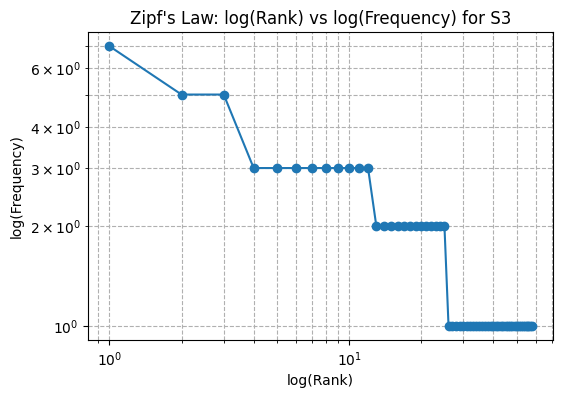

Top 5 bigrams in S1: [(('.', 'i'), 6), (('i', 'have'), 5), (('have', 'tried'), 5), (('tried', 'several'), 5), (('several', 'times'), 5)]
Top 5 bigrams in S3: [(('tried', 'several'), 5), (('several', 'times'), 5), (('please', 'resolve'), 3), (('assignment', 'deadline'), 2), (('matlab', 'keeps'), 2)]


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from nltk.util import ngrams

s1_tokens = []
for _, r in df.iterrows():
    s1_tokens.extend([t.lower() for t in word_tokenize(r["Ticket_Text"])])

s2_tokens = [t for t in s1_tokens if not is_punct(t)]

s3_tokens = []
for _, r in df.iterrows():
    s3_tokens.extend(process_ticket(r["Ticket_Text"])["final"])

ps = PorterStemmer()
s4_tokens = [ps.stem(t) for t in s3_tokens]

def compute_stats(tokens):
    total = len(tokens)
    unique = len(set(tokens))
    ttr = unique / total if total > 0 else 0
    return total, unique, ttr

stats_list = []
for name, toks in [("S1 (All Tokens)", s1_tokens), ("S2 (No Punctuation)", s2_tokens), ("S3 (Final Tokens)", s3_tokens), ("S4 (S3 after Porter)", s4_tokens)]:
    tot, uniq, ttr = compute_stats(toks)
    stats_list.append({"Corpus": name, "Tokens": tot, "Unique Tokens": uniq, "TTR": ttr})

df_corpus_stats = pd.DataFrame(stats_list)
display(df_corpus_stats)

c_s1 = Counter(s1_tokens)
c_s3 = Counter(s3_tokens)

print("Top 10 words in S1:", c_s1.most_common(10))
print("Top 10 words in S3:", c_s3.most_common(10))

s3_counts = sorted(c_s3.values(), reverse=True)
ranks = np.arange(1, len(s3_counts) + 1)

plt.figure(figsize=(6, 4))
plt.loglog(ranks, s3_counts, marker="o", linestyle="-")
plt.title("Zipf's Law: log(Rank) vs log(Frequency) for S3")
plt.xlabel("log(Rank)")
plt.ylabel("log(Frequency)")
plt.grid(True, which="both", ls="--")
plt.show()

bg_s1 = list(ngrams(s1_tokens, 2))
bg_s3 = list(ngrams(s3_tokens, 2))

print("Top 5 bigrams in S1:", Counter(bg_s1).most_common(5))
print("Top 5 bigrams in S3:", Counter(bg_s3).most_common(5))

**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:*